In [1]:
import pandas as pd
import numpy as np
import re
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

In [2]:
# ============================================================
# 1. CONFIG
# ============================================================
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

jobs_clean_path = DATA_DIR / "jobs_clean.csv"

# Output folders for figures and tables
output_folder = PROJECT_ROOT / "output" / "eda_jobs"
figures_folder = output_folder / "figures"
tables_folder = output_folder / "tables"
figures_folder.mkdir(parents=True, exist_ok=True)
tables_folder.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. RESEARCH PARAMETERS
# ============================================================
CITIES = [
    "Toronto",
    "Vancouver",
    "Montreal"
]
ROLES = [
    "Data Analyst",
    "Data Scientist",
    "Data Engineer"
]
SENIORITY_LEVELS = [
    "Intern / Co-op",
    "Junior",
    "Mid / not stated",
    "Senior",
    "Lead / Manager"
]

# Colors used in every chart
CITY_COLORS = {"Toronto": "#1f77b4",
               "Vancouver": "#2ca02c",
               "Montreal": "#d62728"}
ROLE_COLORS = {"Data Analyst": "#4c72b0",
               "Data Scientist": "#dd8452",
               "Data Engineer": "#55a868"}
SOURCE_COLORS = ["#8172b3", "#937860"]

# Minimum number of postings needed in a group to run a statistical test
MIN_GROUP_SIZE = 5

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


In [3]:
# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

#function to inspect a dataset 
def inspect_dataset(df, dataset_name):
    print(f"\n--- {dataset_name} ---")
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Exact duplicate rows:", df.duplicated().sum())

    missing = (df.isna().sum().to_frame("missing_count"))
    missing["missing_percentage"] = (missing["missing_count"] / len(df) * 100).round(2)
    missing["dtype"] = df.dtypes.astype(str)
    missing["unique_values"] = df.nunique()
    display(missing.sort_values("missing_percentage", ascending=False))
    return missing

# Create normalized keys for identifying potential cross-source duplicates.
def normalize_key(value):
    if pd.isna(value):
        return ""
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

#function to estimate the seniority level from the job title
def classify_seniority(value):
    if pd.isna(value):
        return "Mid / not stated"
    value = str(value).strip().lower()
    if re.search(r"\bintern\b|internship|co-?op|stagiaire|student|étudiant", value):
        return "Intern / Co-op"
    elif re.search(r"\blead\b|principal|\bstaff\b|manager|director|\bhead\b|\bvp\b|chef d|gestionnaire|directeur|directrice", value):
        return "Lead / Manager"
    elif re.search(r"\bjunior\b|\bjr\b|entry[- ]level|new grad|débutant|\bassociate\b(?!\s*/?\s*professor)", value):
        return "Junior"
    elif re.search(r"senior|sénior|\bsr\b|\biii\b", value):
        return "Senior"
    return "Mid / not stated"

#function to estimate the work mode from the title, location and description
def classify_work_mode(value):
    if pd.isna(value):
        return "Not stated"
    value = str(value).strip().lower()
    if re.search(r"hybrid|hybride", value):
        return "Hybrid"
    elif re.search(r"\bremote\b|télétravail|work from home|à distance", value):
        return "Remote"
    elif re.search(r"on[- ]?site|in[- ]office|sur place|en présentiel", value):
        return "On-site"
    return "Not stated"

#function to group the original salary period
def group_salary_period(value):
    if pd.isna(value):
        return "Other (converted)"
    value = str(value).strip().lower()
    if value.startswith("annual"):
        return "Annual"
    elif value == "hourly":
        return "Hourly (converted)"
    return "Other (converted)"

#function to summarize the salary midpoint for any grouping
def salary_summary(df, group_columns):
    summary = (df.groupby(group_columns, observed=True)["salary_mid_annual"]
               .agg(total_jobs = "count",
                    median_salary = "median",
                    mean_salary = "mean",
                    q1_salary = lambda s: s.quantile(0.25),
                    q3_salary = lambda s: s.quantile(0.75),
                    min_salary = "min",
                    max_salary = "max"))
    summary["iqr_salary"] = summary["q3_salary"] - summary["q1_salary"]
    return summary.round(0)

#function to flag outliers with the 1.5 x IQR rule
def flag_outliers(salaries):
    q1 = salaries.quantile(0.25)
    q3 = salaries.quantile(0.75)
    iqr = q3 - q1
    return (salaries < q1 - 1.5 * iqr) | (salaries > q3 + 1.5 * iqr)

#function to run a Kruskal-Wallis test between the groups of one column
def kruskal_test(df, group_column, comparison_name):
    result = {"comparison": comparison_name,
              "groups": 0,
              "total_jobs": len(df),
              "h_statistic": np.nan,
              "p_value": np.nan}

    samples = []
    for group_name, group in df.groupby(group_column, observed=True):
        # Skip groups that are too small to compare
        if len(group) >= MIN_GROUP_SIZE:
            samples.append(group["salary_mid_annual"].to_numpy())

    result["groups"] = len(samples)
    if len(samples) < 2:
        return result

    h_statistic, p_value = stats.kruskal(*samples)
    result["h_statistic"] = round(h_statistic, 2)
    result["p_value"] = p_value
    return result

#function to show salaries as $100k in the chart axis
def format_dollars(value, position):
    return f"${value / 1000:,.0f}k"

dollar_format = mtick.FuncFormatter(format_dollars)

#function to save a figure in the output folder
def save_figure(file_name):
    plt.tight_layout()
    plt.savefig(figures_folder / file_name, dpi=200, bbox_inches="tight")
    plt.show()

#function to save a table in the output folder
def save_table(table, file_name, index=True):
    table.to_csv(tables_folder / file_name, index=index, encoding="utf-8-sig")

In [4]:
# ============================================================
# 4. LOAD DATASET
# ============================================================
# source_id is loaded as text because Jooble IDs have 19 digits
# and they get rounded if they are loaded as numbers.
jobs_raw = pd.read_csv(jobs_clean_path, dtype={"source_id": "string"})

print("Jobs clean shape: ", jobs_raw.shape)
display(jobs_raw.head())

Jobs clean shape:  (3558, 22)


,source,source_id,title,company,city_raw,search_position,description,salary_min_raw,salary_max_raw,salary_period,job_type,posted_date,url,collected_at,salary_min_annual,salary_max_annual,salary_original,city,job_role,salary_mid_annual,salary_needs_review,duplicate_candidate
0,Adzuna,5870640464,Data Analyst,Citylitics,"Toronto, Ontario",Data Analyst,About Citylitics Inc. Citylitics delivers pred...,"65,000.00","80,000.00",Annual (assumed by source),full time,2026-09-04 09:55:36.000+00:00,https://www.adzuna.ca/details/5870640464?utm_m...,2026-10-19 01:51:31.278852+00:00,"65,000.00","80,000.00",65000.0 - 80000.0,Toronto,Data Analyst,"72,500.00",False,False
1,Adzuna,5888936887,Data Analyst,WOMBO Studios,"Toronto, Ontario",Data Analyst,About the company Through the latest technique...,"70,000.00","90,000.00",Annual (assumed by source),full time,2026-09-18 04:32:03.000+00:00,https://www.adzuna.ca/details/5888936887?utm_m...,2026-10-19 01:51:31.278852+00:00,"70,000.00","90,000.00",70000.0 - 90000.0,Toronto,Data Analyst,"80,000.00",False,False
2,Adzuna,5718161437,Data Analyst,Acquird.io,"Toronto, Ontario",Data Analyst,"Data Analyst Role : Full-time, on-site 4 days/...","70,000.00","80,000.00",Annual (assumed by source),full time,2026-05-03 16:44:34.000+00:00,https://www.adzuna.ca/details/5718161437?utm_m...,2026-10-19 01:51:31.278852+00:00,"70,000.00","80,000.00",70000.0 - 80000.0,Toronto,Data Analyst,"75,000.00",False,True
3,Adzuna,5933128979,Data Analyst,Konrad,"Toronto, Ontario",Data Analyst,Who We Are Konrad is an AI-driven digital cons...,"75,000.00","100,000.00",Annual (assumed by source),full time,2026-10-18 04:51:47.000+00:00,https://www.adzuna.ca/details/5933128979?utm_m...,2026-10-19 01:51:31.278852+00:00,"75,000.00","100,000.00",75000.0 - 100000.0,Toronto,Data Analyst,"87,500.00",False,True
4,Adzuna,5834738229,Data Analyst,CI Financial,"Toronto, Ontario",Data Analyst,"At CI, we see a great place to work as one tha...","55,000.00","95,000.00",Annual (assumed by source),full time,2026-08-09 11:04:24.000+00:00,https://www.adzuna.ca/details/5834738229?utm_m...,2026-10-19 01:51:31.278852+00:00,"55,000.00","95,000.00",55000.0 - 95000.0,Toronto,Data Analyst,"75,000.00",False,False


In [5]:
structure_report = inspect_dataset(jobs_raw, "Jobs Clean Dataset")
save_table(structure_report, "01_structure_report.csv")

print("Duplicate URLs:", jobs_raw["url"].duplicated().sum())
print("Records with a missing salary midpoint:", jobs_raw["salary_mid_annual"].isna().sum())
print("Records flagged for salary review:", jobs_raw["salary_needs_review"].sum())
print("Potential cross-source duplicate records:", jobs_raw["duplicate_candidate"].sum())

print("\nRows by source:")
display(jobs_raw["source"].value_counts(dropna=False))

print("\nRows by city:")
display(jobs_raw["city"].value_counts(dropna=False))

print("\nRows by job role:")
display(jobs_raw["job_role"].value_counts(dropna=False))

print("\nRows by salary period:")
display(jobs_raw["salary_period"].value_counts(dropna=False))

print("\nRows by job type:")
display(jobs_raw["job_type"].value_counts(dropna=False))


--- Jobs Clean Dataset ---
Rows: 3558
Columns: 22
Exact duplicate rows: 0


,missing_count,missing_percentage,dtype,unique_values
salary_min_raw,2585,72.65,float64,334
salary_max_raw,2585,72.65,float64,336
job_type,1168,32.83,str,7
posted_date,294,8.26,str,1595
company,135,3.79,str,1352
collected_at,0,0.00,str,109
salary_needs_review,0,0.00,bool,2
salary_mid_annual,0,0.00,float64,1054
job_role,0,0.00,str,3
city,0,0.00,str,3


Duplicate URLs: 0
Records with a missing salary midpoint: 0
Records flagged for salary review: 20
Potential cross-source duplicate records: 517

Rows by source:


source
Jooble    2585
Adzuna     973
Name: count, dtype: int64


Rows by city:


city
Toronto      1679
Vancouver    1333
Montreal      546
Name: count, dtype: int64

... (2 outputs left out)


Rows by salary period:


salary_period
Annual                        2189
Annual (assumed by source)     973
Hourly                         347
Monthly                         33
Daily                           10
Weekly                           6
Name: count, dtype: int64


Rows by job type:


job_type
full-time               1430
NaN                     1168
full time                856
temporary                 90
part time                  8
part-time                  4
full-time, temporary       1
full-time, part-time       1
Name: count, dtype: int64

In [6]:
# ============================================================
# 5. PREPARE DATASET FOR THE EDA
# ============================================================
jobs = jobs_raw.copy()

### Standardizing dates and job type
jobs["posted_date"] = pd.to_datetime(jobs["posted_date"], errors="coerce", utc=True)
jobs["collected_at"] = pd.to_datetime(jobs["collected_at"], errors="coerce", utc=True)
jobs["posted_month"] = jobs["posted_date"].dt.tz_localize(None).dt.to_period("M")

# "full time" and "full-time" are the same job type
jobs["job_type"] = (jobs["job_type"].str.lower().str.replace("full time", "full-time", regex=False)
                    .str.replace("part time", "part-time", regex=False).str.strip().fillna("not stated"))

### Creating helper columns
# Width of the advertised salary range
jobs["salary_range_width"] = jobs["salary_max_annual"] - jobs["salary_min_annual"]

# Seniority level estimated from the title
jobs["seniority"] = jobs["title"].apply(classify_seniority)

# Work mode estimated from the title, location and description
jobs["work_mode"] = (jobs["title"].fillna("") + " " + jobs["city_raw"].fillna("") + " " + jobs["description"].fillna("")).apply(classify_work_mode)

# Original salary period grouped in three categories
jobs["salary_period_group"] = jobs["salary_period"].apply(group_salary_period)

# Flag titles that contain a data-related term
data_terms = r"data|donn[ée]es|analytics|analytique|machine learning|\bml\b|\bai\b|\bia\b|\bbi\b|business intelligence|\betl\b"
jobs["title_has_data_term"] = jobs["title"].str.lower().str.contains(data_terms, regex=True, na=False)

# Keep the same order of cities, roles and seniority levels in every table and chart
jobs["city"] = pd.Categorical(jobs["city"], categories=CITIES, ordered=True)
jobs["job_role"] = pd.Categorical(jobs["job_role"], categories=ROLES, ordered=True)
jobs["seniority"] = pd.Categorical(jobs["seniority"], categories=SENIORITY_LEVELS, ordered=True)

print("Records before filtering:", len(jobs))

### Removing records flagged for salary review
jobs = jobs.loc[~jobs["salary_needs_review"]].copy()
records_after_review = len(jobs)
print("Records after removing salaries flagged for review:", records_after_review)

### Keeping only one record per cross-source duplicate group
jobs["title_key"] = jobs["title"].apply(normalize_key)
jobs["company_key"] = jobs["company"].apply(normalize_key)

# Adzuna record is kept first because its salary is numeric at the source
jobs["source_order"] = jobs["source"].map({"Adzuna": 0, "Jooble": 1})
jobs = jobs.sort_values(["source_order", "posted_date"], ascending=[True, False])

repeated_record = (jobs["duplicate_candidate"]& jobs.duplicated(subset=["title_key", "company_key", "city"], keep="first"))
jobs = jobs.loc[~repeated_record].copy()

# Removing helper columns used only for duplicate matching
jobs = jobs.drop(columns=["title_key", "company_key", "source_order"], errors="ignore").reset_index(drop=True)
print("Records after keeping one record per duplicate group:", len(jobs))

# Summary of the records used in the EDA
eda_sample_summary = pd.DataFrame({"Metric": ["Records in jobs_clean.csv",
                                              "Records after removing salaries flagged for review",
                                              "Records after keeping one record per duplicate group"],
                                   "Value": [len(jobs_raw),
                                             records_after_review,
                                             len(jobs)]})
display(eda_sample_summary)
save_table(eda_sample_summary, "02_eda_sample_summary.csv", index=False)

Records before filtering: 3558
Records after removing salaries flagged for review: 3538
Records after keeping one record per duplicate group: 3378


,Metric,Value
0,Records in jobs_clean.csv,3558
1,Records after removing salaries flagged for re...,3538
2,Records after keeping one record per duplicate...,3378


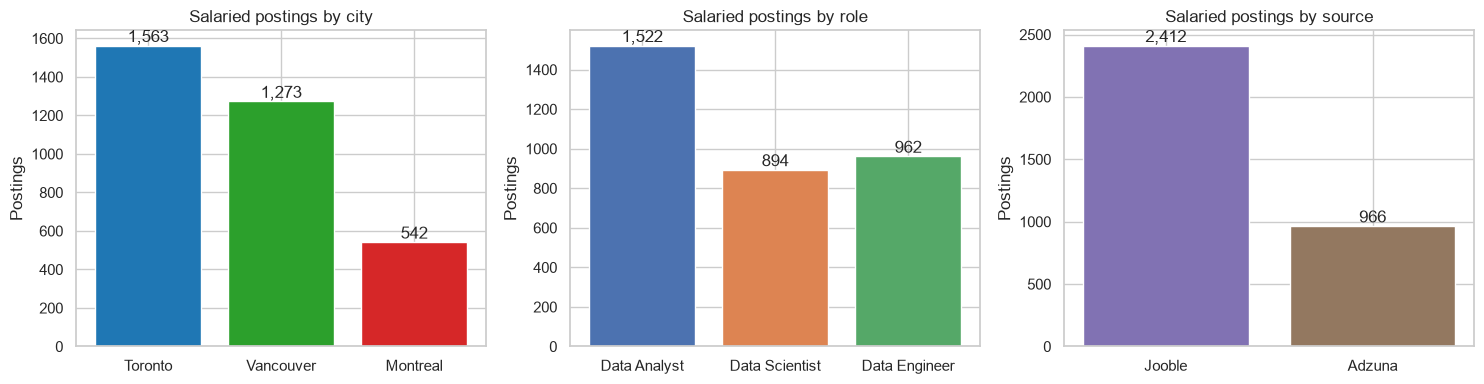

job_role,Data Analyst,Data Scientist,Data Engineer,Total
city,,,,
Toronto,612,445,506,1563
Vancouver,685,264,324,1273
Montreal,225,185,132,542
Total,1522,894,962,3378


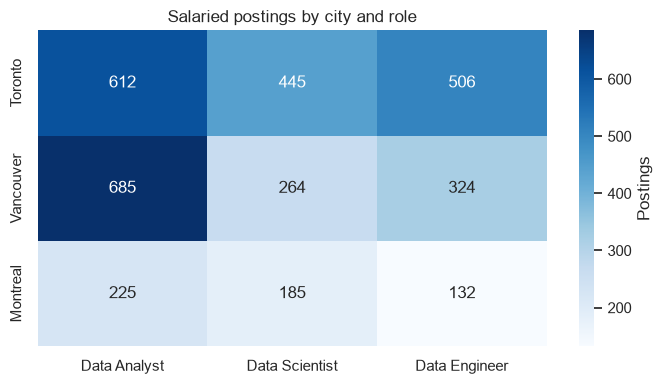

In [7]:
# ============================================================
# 6. SAMPLE COMPOSITION
# ============================================================
# jobs_clean.csv only has postings WITH salary, so these counts are salaried postings, 
# not the total job availability.

# --------------COUNTS BY CITY, ROLE AND SOURCE-----------------
city_counts = jobs["city"].value_counts().reindex(CITIES)
role_counts = jobs["job_role"].value_counts().reindex(ROLES)
source_counts = jobs["source"].value_counts()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(city_counts.index, city_counts.values, color=[CITY_COLORS[city] for city in CITIES])
axes[0].set_title("Salaried postings by city")
axes[1].bar(role_counts.index, role_counts.values, color=[ROLE_COLORS[role] for role in ROLES])
axes[1].set_title("Salaried postings by role")
axes[2].bar(source_counts.index, source_counts.values, color=SOURCE_COLORS)
axes[2].set_title("Salaried postings by source")

for ax in axes:
    ax.set_ylabel("Postings")
    # Write the number of postings above each bar
    for bar in ax.patches:
        ax.annotate(f"{int(bar.get_height()):,}",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom")
save_figure("01_counts_city_role_source.png")

# --------------CITY X ROLE-----------------
city_role_counts = pd.crosstab(jobs["city"], jobs["job_role"], margins=True, margins_name="Total")
display(city_role_counts)
save_table(city_role_counts, "03_counts_city_role.csv")

plt.figure(figsize=(7, 4))
sns.heatmap(pd.crosstab(jobs["city"], jobs["job_role"]), annot=True, fmt=",d", cmap="Blues", cbar_kws={"label": "Postings"})
plt.title("Salaried postings by city and role")
plt.xlabel("")
plt.ylabel("")
save_figure("02_heatmap_counts_city_role.png")

source,Adzuna,Jooble
city,,
Toronto,39.70,60.30
Vancouver,22.60,77.40
Montreal,10.50,89.50


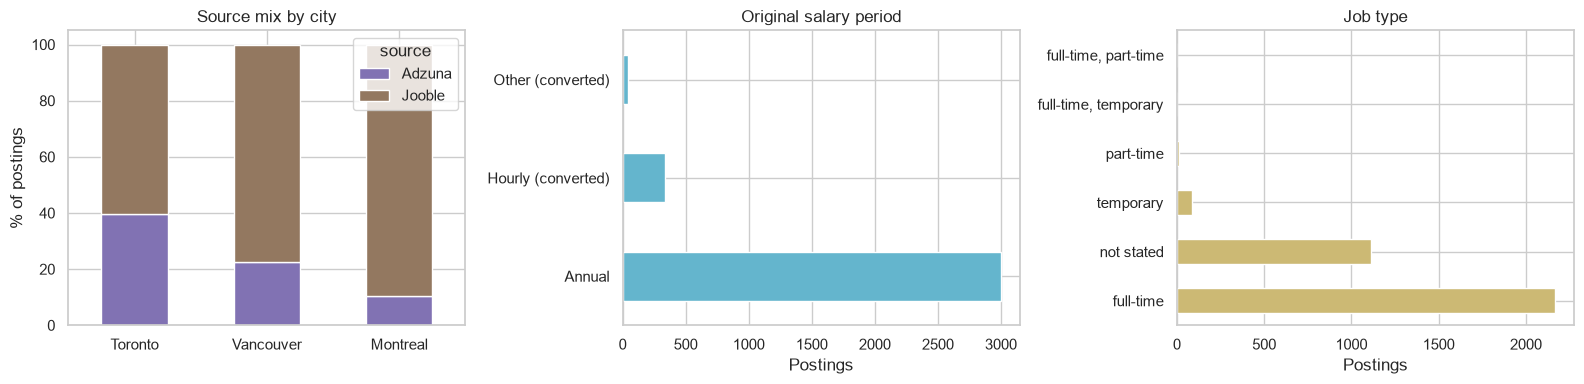

In [8]:
# --------------SOURCE, SALARY PERIOD AND JOB TYPE-----------------
source_by_city = (pd.crosstab(jobs["city"], jobs["source"], normalize="index") * 100).round(1)
display(source_by_city)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
source_by_city.plot(kind="bar", stacked=True, ax=axes[0], color=SOURCE_COLORS, rot=0)
axes[0].set_title("Source mix by city")
axes[0].set_ylabel("% of postings")
axes[0].set_xlabel("")

jobs["salary_period_group"].value_counts().plot(kind="barh", ax=axes[1], color="#64b5cd")
axes[1].set_title("Original salary period")
axes[1].set_xlabel("Postings")
axes[1].set_ylabel("")

jobs["job_type"].value_counts().plot(kind="barh", ax=axes[2], color="#ccb974")
axes[2].set_title("Job type")
axes[2].set_xlabel("Postings")
axes[2].set_ylabel("")
save_figure("03_source_period_jobtype.png")

Salary summary:


,salary_min_annual,salary_max_annual,salary_mid_annual
count,"3,378.00","3,378.00","3,378.00"
mean,"111,774.86","144,876.85","128,325.85"
std,"48,134.09","63,758.35","54,472.39"
min,"16,000.00","16,640.00","16,640.00"
25%,"75,700.00","98,325.00","87,750.00"
50%,"103,000.00","136,000.00","120,000.00"
75%,"140,000.00","180,000.00","160,000.00"
max,"418,920.00","425,000.00","418,920.00"


Skewness of the salary midpoint: 0.99


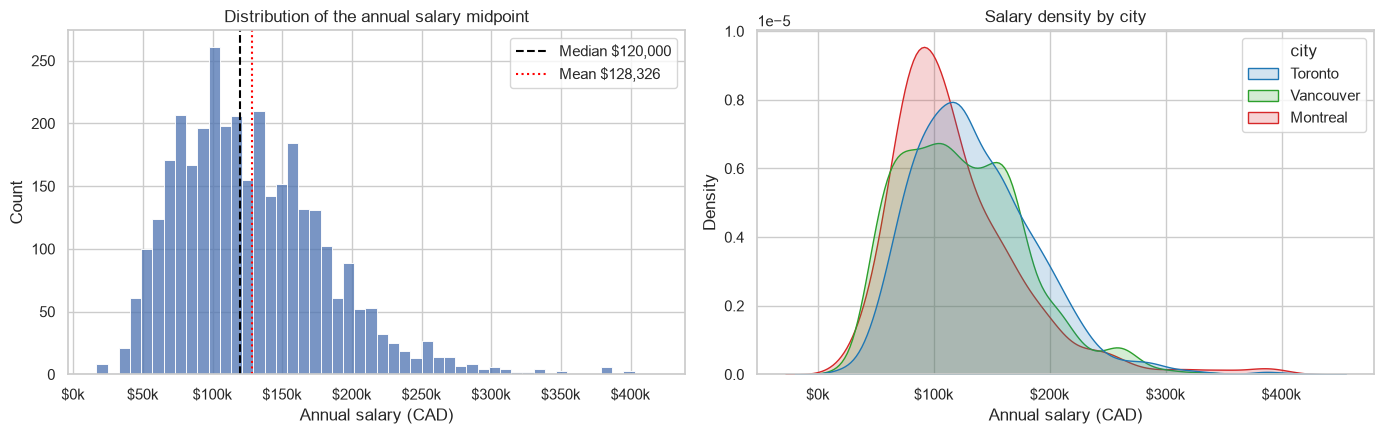

In [9]:
# ============================================================
# 7. SALARY ANALYSIS
# ============================================================
# salary_mid_annual is the main salary measure.
# Salaries are right-skewed, so the median is used before the mean.

# --------------OVERALL DISTRIBUTION-----------------
print("Salary summary:")
display(jobs[["salary_min_annual", "salary_max_annual", "salary_mid_annual"]].describe().round(2))
print("Skewness of the salary midpoint:", round(jobs["salary_mid_annual"].skew(), 2))

median_salary = jobs["salary_mid_annual"].median()
mean_salary = jobs["salary_mid_annual"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(jobs["salary_mid_annual"], bins=50, ax=axes[0], color="#4c72b0")
axes[0].axvline(median_salary, color="black", linestyle="--", label=f"Median ${median_salary:,.0f}")
axes[0].axvline(mean_salary, color="red", linestyle=":", label=f"Mean ${mean_salary:,.0f}")
axes[0].xaxis.set_major_formatter(dollar_format)
axes[0].set_title("Distribution of the annual salary midpoint")
axes[0].set_xlabel("Annual salary (CAD)")
axes[0].legend()

sns.kdeplot(data=jobs, x="salary_mid_annual", hue="city", hue_order=CITIES, palette=CITY_COLORS,
            common_norm=False, fill=True, alpha=0.2, ax=axes[1])
axes[1].xaxis.set_major_formatter(dollar_format)
axes[1].set_title("Salary density by city")
axes[1].set_xlabel("Annual salary (CAD)")
save_figure("04_salary_distribution.png")

In [10]:
# --------------SALARY BY CITY, ROLE AND CITY X ROLE-----------------
salary_by_city = salary_summary(jobs, "city")
salary_by_role = salary_summary(jobs, "job_role")
salary_by_city_role = salary_summary(jobs, ["city", "job_role"])

print("Salary by city:")
display(salary_by_city)

print("\nSalary by job role:")
display(salary_by_role)

print("\nSalary by city and job role:")
display(salary_by_city_role)

save_table(salary_by_city, "04_salary_by_city.csv")
save_table(salary_by_role, "05_salary_by_role.csv")
save_table(salary_by_city_role, "06_salary_by_city_role.csv")

Salary by city:


,total_jobs,median_salary,mean_salary,q1_salary,q3_salary,min_salary,max_salary,iqr_salary
city,,,,,,,,
Toronto,1563,"126,750.00","134,638.00","95,615.00","165,450.00","16,640.00","418,920.00","69,835.00"
Vancouver,1273,"118,500.00","124,748.00","82,500.00","159,950.00","20,000.00","400,000.00","77,450.00"
Montreal,542,"104,994.00","118,526.00","80,000.00","142,500.00","20,000.00","400,000.00","62,500.00"



Salary by job role:


,total_jobs,median_salary,mean_salary,q1_salary,q3_salary,min_salary,max_salary,iqr_salary
job_role,,,,,,,,
Data Analyst,1522,"102,000.00","112,759.00","77,500.00","137,375.00","16,640.00","400,000.00","59,875.00"
Data Scientist,894,"131,812.00","133,938.00","92,500.00","165,300.00","20,000.00","418,920.00","72,800.00"
Data Engineer,962,"141,278.00","147,738.00","110,688.00","175,000.00","20,000.00","400,000.00","64,312.00"



Salary by city and job role:


total_jobs  median_salary  mean_salary  q1_salary  \
city      job_role                                                            
Toronto   Data Analyst           612     102,500.00   116,139.00  80,000.00   
          Data Scientist         445     135,250.00   141,664.00 105,500.00   
          Data Engineer          506     145,000.00   150,834.00 115,000.00   
Vancouver Data Analyst           685     105,000.00   113,773.00  75,000.00   
          Data Scientist         264     137,000.00   131,747.00  79,375.00   
          Data Engineer          324     139,488.00   142,249.00 107,500.00   
Montreal  Data Analyst           225      90,000.00   100,481.00  76,500.00   
          Data Scientist         185     107,250.00   118,482.00  80,000.00   
          Data Engineer          132     140,000.00   149,346.00 105,000.00   

                          q3_salary  min_salary  max_salary  iqr_salary  
city      job_role                                                       
Toronto   Data Analyst   143,250.00   16,640.00  300,000.00   63,250.00  
          Data Scientist 170,000.00   35,002.00  418,920.00   64,500.00  
          Data Engineer  178,950.00   43,890.00  400,000.00   63,950.00  
Vancouver Data Analyst   143,500.00   20,000.00  400,000.00   68,500.00  
          Data Scientist 170,000.00   41,925.00  300,000.00   90,625.00  
          Data Engineer  170,000.00   20,000.00  332,800.00   62,500.00  
Montreal  Data Analyst   112,650.00   25,000.00  317,450.00   36,150.00  
          Data Scientist 145,000.00   20,000.00  400,000.00   65,000.00  
          Data Engineer  180,125.00   42,900.00  384,800.00   75,125.00

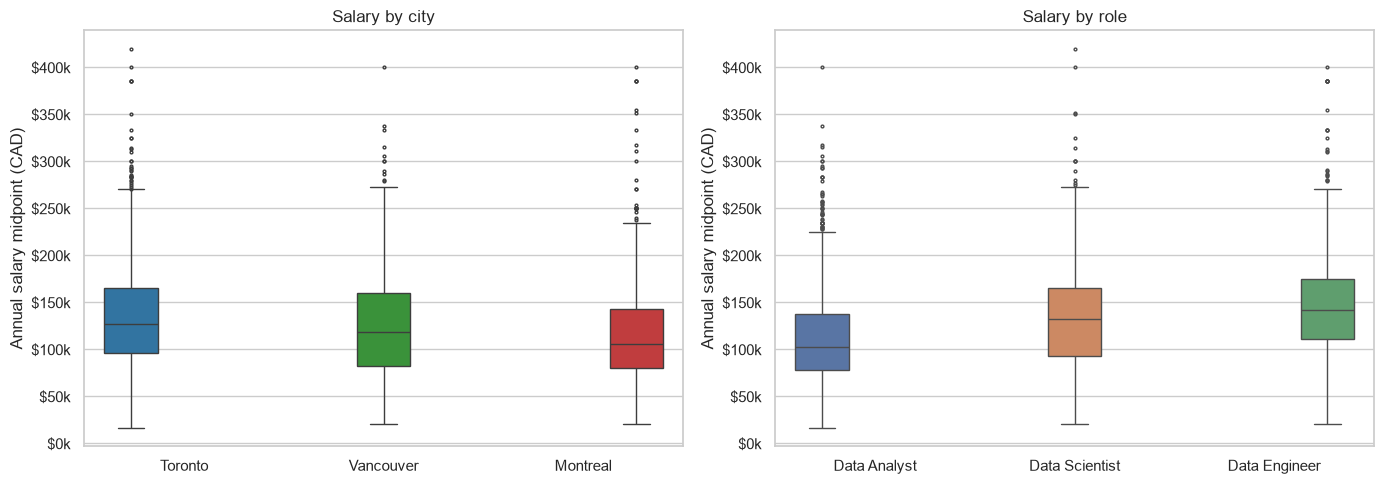

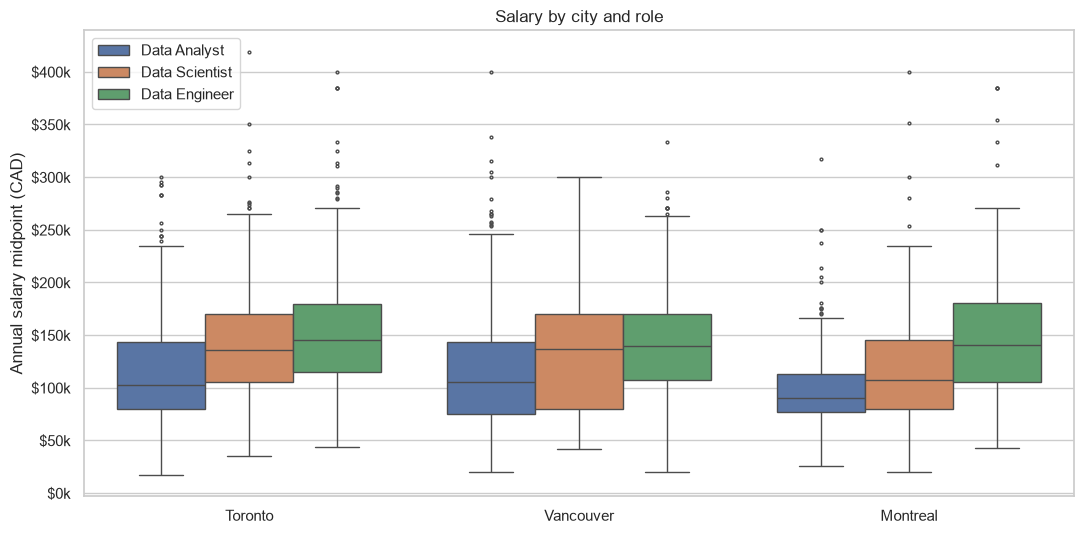

In [11]:
# --------------BOXPLOTS-----------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=jobs, x="city", y="salary_mid_annual", order=CITIES, hue="city", palette=CITY_COLORS,
            legend=False, fliersize=2, ax=axes[0])
axes[0].set_title("Salary by city")

sns.boxplot(data=jobs, x="job_role", y="salary_mid_annual", order=ROLES, hue="job_role", palette=ROLE_COLORS,
            legend=False, fliersize=2, ax=axes[1])
axes[1].set_title("Salary by role")

for ax in axes:
    ax.yaxis.set_major_formatter(dollar_format)
    ax.set_xlabel("")
    ax.set_ylabel("Annual salary midpoint (CAD)")
save_figure("05_boxplots_city_and_role.png")

plt.figure(figsize=(11, 5.5))
ax = sns.boxplot(data=jobs, x="city", y="salary_mid_annual", hue="job_role", order=CITIES,
                 hue_order=ROLES, palette=ROLE_COLORS, fliersize=2)
ax.yaxis.set_major_formatter(dollar_format)
ax.set_title("Salary by city and role")
ax.set_xlabel("")
ax.set_ylabel("Annual salary midpoint (CAD)")
ax.legend(title="")
save_figure("06_boxplot_city_by_role.png")

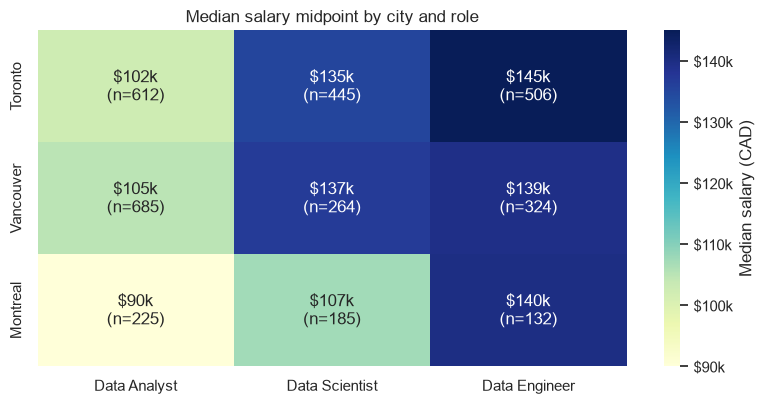

In [12]:
# --------------MEDIAN SALARY HEATMAP-----------------
median_table = jobs.pivot_table(index="city", columns="job_role", values="salary_mid_annual", aggfunc="median", observed=True)
count_table = jobs.pivot_table(index="city", columns="job_role", values="salary_mid_annual", aggfunc="count", observed=True)

# Each cell shows the median salary and the number of postings behind it
heatmap_labels = median_table.copy().astype(object)
for city in median_table.index:
    for role in median_table.columns:
        heatmap_labels.loc[city, role] = (f"${median_table.loc[city, role] / 1000:,.0f}k\n"
                                          f"(n={int(count_table.loc[city, role])})")

plt.figure(figsize=(8, 4.2))
sns.heatmap(median_table, annot=heatmap_labels, fmt="", cmap="YlGnBu",
            cbar_kws={"label": "Median salary (CAD)", "format": dollar_format})
plt.title("Median salary midpoint by city and role")
plt.xlabel("")
plt.ylabel("")
save_figure("07_heatmap_median_salary.png")

total_jobs  median_min_salary  median_max_salary  \
city      job_role                                                           
Toronto   Data Analyst           612          92,668.00         116,550.00   
          Data Scientist         445         120,000.00         150,000.00   
          Data Engineer          506         124,900.00         160,000.00   
Vancouver Data Analyst           685          90,422.00         120,000.00   
          Data Scientist         264         114,800.00         155,500.00   
          Data Engineer          324         116,740.00         160,000.00   
Montreal  Data Analyst           225          75,406.00         110,000.00   
          Data Scientist         185          95,000.00         122,000.00   
          Data Engineer          132         120,000.00         159,900.00   

                          median_range_width  single_value_percentage  
city      job_role                                                     
Toronto   Data Analyst             20,000.00                    19.00  
          Data Scientist           30,000.00                    12.00  
          Data Engineer            35,000.00                     5.00  
Vancouver Data Analyst             22,000.00                     8.00  
          Data Scientist           30,000.00                    15.00  
          Data Engineer            35,000.00                     7.00  
Montreal  Data Analyst             21,300.00                    17.00  
          Data Scientist           20,000.00                    19.00  
          Data Engineer            23,000.00                    22.00

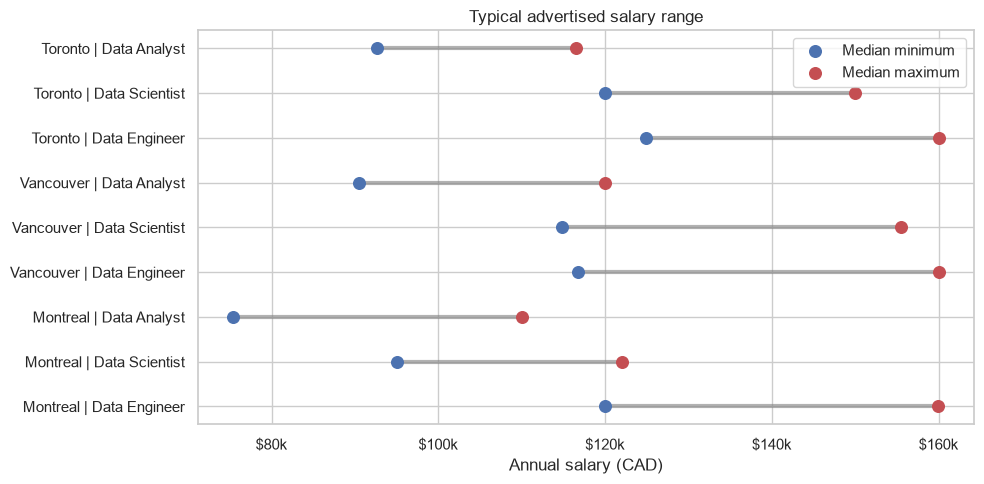

In [13]:
# --------------ADVERTISED SALARY RANGE-----------------
# Typical minimum and maximum advertised for each city and role
salary_range = (jobs.groupby(["city", "job_role"], observed=True)
                .agg(total_jobs = ("salary_mid_annual", "count"),
                     median_min_salary = ("salary_min_annual", "median"),
                     median_max_salary = ("salary_max_annual", "median"),
                     median_range_width = ("salary_range_width", "median"),
                     single_value_percentage = ("salary_range_width", lambda s: (s == 0).mean() * 100)).round(0))
display(salary_range)
save_table(salary_range, "07_salary_range_by_city_role.csv")

range_plot = salary_range.reset_index()
range_plot["label"] = range_plot["city"].astype(str) + " | " + range_plot["job_role"].astype(str)
range_plot = range_plot.iloc[::-1]

plt.figure(figsize=(10, 5))
plt.hlines(range_plot["label"], range_plot["median_min_salary"], range_plot["median_max_salary"], color="grey", linewidth=3, alpha=0.6)
plt.scatter(range_plot["median_min_salary"], range_plot["label"], color="#4c72b0", s=70, label="Median minimum", zorder=3)
plt.scatter(range_plot["median_max_salary"], range_plot["label"], color="#c44e52", s=70, label="Median maximum", zorder=3)
plt.gca().xaxis.set_major_formatter(dollar_format)
plt.title("Typical advertised salary range")
plt.xlabel("Annual salary (CAD)")
plt.legend()
save_figure("08_salary_range.png")

In [14]:
# --------------OUTLIERS-----------------
# Outliers are flagged inside each city x role group. They are NOT removed.
jobs["salary_outlier"] = (jobs.groupby(["city", "job_role"], observed=True)["salary_mid_annual"].transform(flag_outliers))

outlier_report = (jobs.groupby(["city", "job_role"], observed=True)
                  .agg(total_jobs = ("title", "size"),
                       salary_outliers = ("salary_outlier", "sum")))
outlier_report["outlier_percentage"] = (outlier_report["salary_outliers"] / outlier_report["total_jobs"] * 100).round(1)
display(outlier_report)
save_table(outlier_report, "08_outliers_by_city_role.csv")

review_columns = ["source", "city", "job_role", "title", "company", "salary_original", "salary_period", "salary_mid_annual"]

print("Highest salaries flagged as outliers:")
display(jobs.loc[jobs["salary_outlier"], review_columns].sort_values("salary_mid_annual", ascending=False).head(10))

print("Lowest salaries in the dataset:")
display(jobs[review_columns].sort_values("salary_mid_annual").head(10))

total_jobs  salary_outliers  outlier_percentage
city      job_role                                                       
Toronto   Data Analyst           612               13                2.10
          Data Scientist         445               10                2.20
          Data Engineer          506               14                2.80
Vancouver Data Analyst           685               14                2.00
          Data Scientist         264                0                0.00
          Data Engineer          324                8                2.50
Montreal  Data Analyst           225               13                5.80
          Data Scientist         185                5                2.70
          Data Engineer          132                6                4.50

Highest salaries flagged as outliers:


,source,city,job_role,title,company,salary_original,salary_period,salary_mid_annual
3284,Jooble,Toronto,Data Scientist,Assistant/ Associate/ Professor - Gastrointest...,University of Toronto,$418.92k per year,Annual,"418,920.00"
1957,Jooble,Vancouver,Data Analyst,Machine Learning Engineer => Relocate to China,MS Systems,$400k per year,Annual,"400,000.00"
1965,Jooble,Montreal,Data Scientist,Machine Learning Engineer => Relocate to China,MS Systems,$400k per year,Annual,"400,000.00"
1967,Jooble,Toronto,Data Engineer,Machine Learning Engineer => Relocate to China,MS Systems,$400k per year,Annual,"400,000.00"
67,Adzuna,Toronto,Data Engineer,Python/Typescript Engineer,Turing,353600.0 - 416000.0,Annual (assumed by source),"384,800.00"
68,Adzuna,Toronto,Data Engineer,Typescript Engineer,Turing,353600.0 - 416000.0,Annual (assumed by source),"384,800.00"
69,Adzuna,Montreal,Data Engineer,Python/Typescript Engineer,Turing,353600.0 - 416000.0,Annual (assumed by source),"384,800.00"
70,Adzuna,Montreal,Data Engineer,Python Engineer,Turing,353600.0 - 416000.0,Annual (assumed by source),"384,800.00"
71,Adzuna,Montreal,Data Engineer,Typescript Engineer,Turing,353600.0 - 416000.0,Annual (assumed by source),"384,800.00"
66,Adzuna,Toronto,Data Engineer,Python Engineer,Turing,353600.0 - 416000.0,Annual (assumed by source),"384,800.00"


Lowest salaries in the dataset:


,source,city,job_role,title,company,salary_original,salary_period,salary_mid_annual
146,Adzuna,Toronto,Data Analyst,"Product Owner, Data & Analytics",Mattamy Homes,16640.0 - 16640.0,Annual (assumed by source),"16,640.00"
3174,Jooble,Toronto,Data Analyst,IRE2004HS - Data Analytics and Metrics for IR ...,University of Toronto,$19.99k per year,Annual,"19,990.00"
2883,Jooble,Toronto,Data Analyst,Risk Analyst,Relay,$20k per year,Annual,"20,000.00"
2533,Jooble,Montreal,Data Scientist,Software Developer (hybrid Montreal),Calliere,$20k per year,Annual,"20,000.00"
2366,Jooble,Vancouver,Data Engineer,GTM Integration Engineer III,Zoominfo,$20k per year,Annual,"20,000.00"
2362,Jooble,Vancouver,Data Analyst,Senior GTM Success Manager,Zoominfo,$20k per year,Annual,"20,000.00"
2000,Jooble,Vancouver,Data Analyst,GTM Delivery Analyst,Zoominfo,$20k per year,Annual,"20,000.00"
786,Adzuna,Toronto,Data Analyst,Part-Time Lecturer - Analytics (Toronto),Northeastern University,24593.0 - 24593.0,Annual (assumed by source),"24,593.00"
1263,Jooble,Montreal,Data Analyst,"Directeur Général, Développement Corporatif",GardaWorld,$25k per year,Annual,"25,000.00"
3096,Jooble,Toronto,Data Analyst,Accounts Payable Analyst,NaN,$17 per hour,Hourly,"33,150.00"


total_jobs        median_salary           
source                       Adzuna Jooble        Adzuna     Jooble
city      job_role                                                 
Toronto   Data Analyst           99    513     98,725.00 105,000.00
          Data Scientist        285    160    136,000.00 135,000.00
          Data Engineer         237    269    137,750.00 150,000.00
Vancouver Data Analyst           30    655    110,250.00 105,000.00
          Data Scientist        156    108    132,525.00 152,900.00
          Data Engineer         102    222    128,750.00 145,000.00
Montreal  Data Analyst           11    214     93,600.00  90,000.00
          Data Scientist         21    164    120,000.00 105,000.00
          Data Engineer          25    107    130,000.00 141,375.00

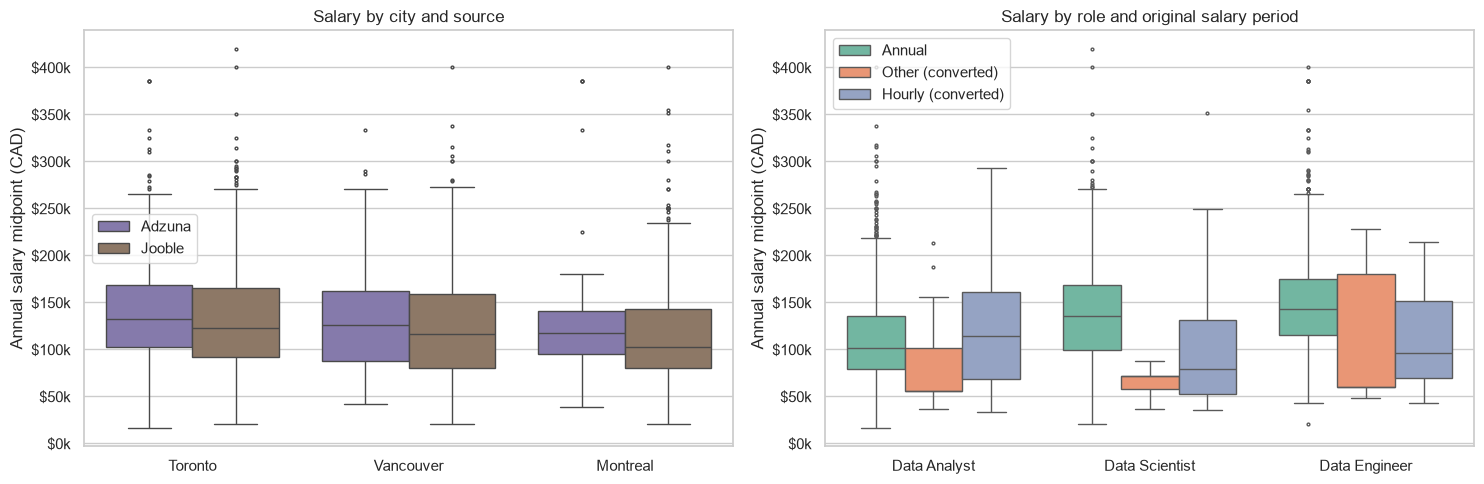

In [15]:
# ============================================================
# 8. SOURCE, SALARY PERIOD AND SENIORITY
# ============================================================

# --------------ADZUNA VS JOOBLE-----------------
# If both sources show different salaries, the results depend on the source mix.
salary_by_source = (jobs.groupby(["city", "job_role", "source"], observed=True)
                    .agg(total_jobs = ("salary_mid_annual", "count"),
                         median_salary = ("salary_mid_annual", "median")).round(0).unstack("source"))
display(salary_by_source)
save_table(salary_by_source, "09_salary_by_source.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=jobs, x="city", y="salary_mid_annual", hue="source", order=CITIES,
            palette=SOURCE_COLORS, fliersize=2, ax=axes[0])
axes[0].set_title("Salary by city and source")

sns.boxplot(data=jobs, x="job_role", y="salary_mid_annual", hue="salary_period_group", order=ROLES,
            palette="Set2", fliersize=2, ax=axes[1])
axes[1].set_title("Salary by role and original salary period")

for ax in axes:
    ax.yaxis.set_major_formatter(dollar_format)
    ax.set_xlabel("")
    ax.set_ylabel("Annual salary midpoint (CAD)")
    ax.legend(title="")
save_figure("09_salary_by_source_and_period.png")

Seniority mix by job role (%):


seniority,Intern / Co-op,Junior,Mid / not stated,Senior,Lead / Manager
job_role,,,,,
Data Analyst,2.40,2.90,52.20,19.60,22.90
Data Scientist,4.60,3.70,42.50,18.60,30.60
Data Engineer,1.70,1.80,43.20,24.70,28.60



Seniority mix by city (%):


seniority,Intern / Co-op,Junior,Mid / not stated,Senior,Lead / Manager
city,,,,,
Toronto,2.00,2.20,46.30,26.00,23.50
Vancouver,4.20,3.30,41.50,17.20,33.90
Montreal,1.70,3.30,62.70,14.00,18.30


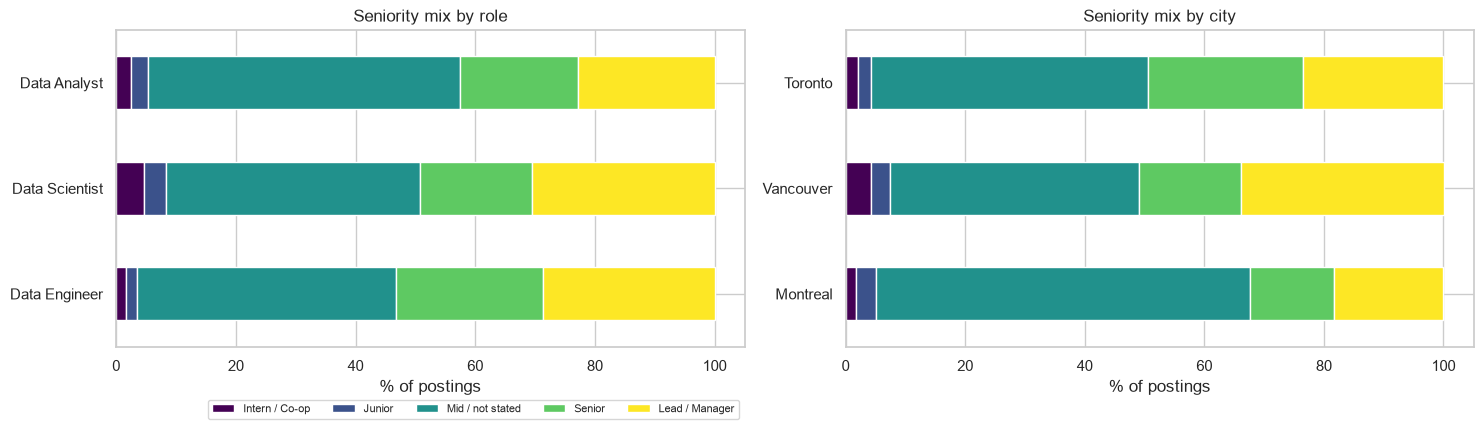

Salary by seniority:


,total_jobs,median_salary,mean_salary,q1_salary,q3_salary,min_salary,max_salary,iqr_salary
seniority,,,,,,,,
Intern / Co-op,93,"55,000.00","62,159.00","48,750.00","65,748.00","35,002.00","160,990.00","16,998.00"
Junior,94,"80,005.00","92,062.00","61,250.00","104,750.00","38,415.00","351,000.00","43,500.00"
Mid / not stated,1591,"102,500.00","113,807.00","76,018.00","136,825.00","16,640.00","418,920.00","60,808.00"
Senior,702,"132,500.00","136,009.00","108,000.00","161,962.00","20,000.00","310,000.00","53,962.00"
Lead / Manager,898,"154,900.00","158,692.00","123,756.00","188,000.00","20,000.00","350,000.00","64,244.00"



Salary by seniority and city:


total_jobs                    median_salary             \
city                Toronto Vancouver Montreal       Toronto  Vancouver   
seniority                                                                 
Intern / Co-op           31        53        9     55,746.00  54,356.00   
Junior                   34        42       18     81,120.00  73,450.00   
Mid / not stated        723       528      340    110,000.00  92,300.00   
Senior                  407       219       76    128,000.00 145,000.00   
Lead / Manager          368       431       99    159,750.00 152,500.00   

                             
city               Montreal  
seniority                    
Intern / Co-op    54,925.00  
Junior            88,110.00  
Mid / not stated  97,500.00  
Senior           115,129.00  
Lead / Manager   139,444.00

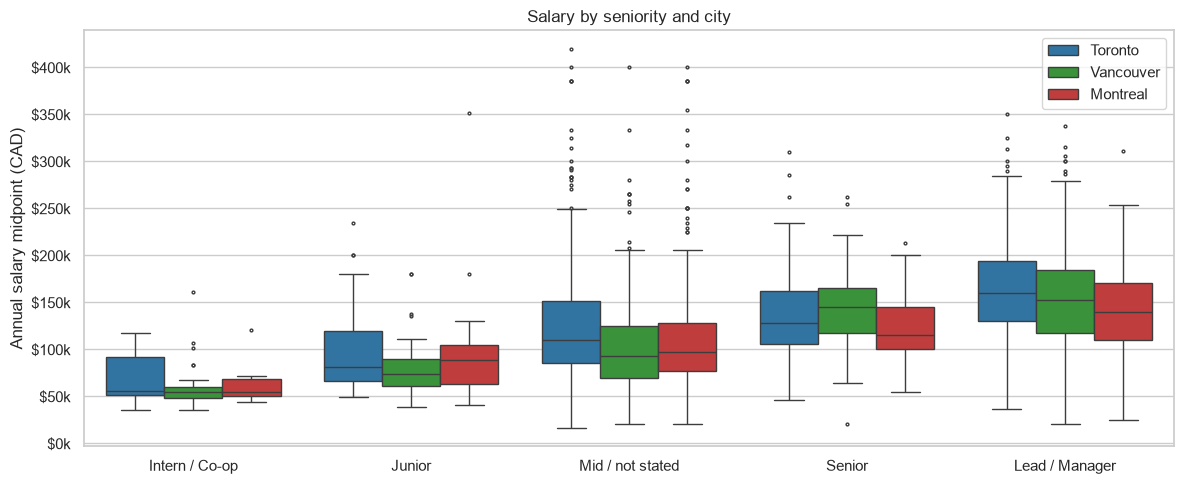

In [16]:
# --------------SENIORITY-----------------
# Seniority is estimated from keywords in the title, so it is an approximation.
seniority_by_role = (pd.crosstab(jobs["job_role"], jobs["seniority"], normalize="index") * 100).round(1)
seniority_by_city = (pd.crosstab(jobs["city"], jobs["seniority"], normalize="index") * 100).round(1)

print("Seniority mix by job role (%):")
display(seniority_by_role)

print("\nSeniority mix by city (%):")
display(seniority_by_city)

save_table(seniority_by_role, "10_seniority_by_role.csv")
save_table(seniority_by_city, "11_seniority_by_city.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
seniority_by_role.plot(kind="barh", stacked=True, ax=axes[0], colormap="viridis")
axes[0].set_title("Seniority mix by role")
axes[0].set_xlabel("% of postings")
axes[0].set_ylabel("")
axes[0].invert_yaxis()
axes[0].legend(title="", bbox_to_anchor=(1.0, -0.15), ncol=5, fontsize=8)

seniority_by_city.plot(kind="barh", stacked=True, ax=axes[1], colormap="viridis", legend=False)
axes[1].set_title("Seniority mix by city")
axes[1].set_xlabel("% of postings")
axes[1].set_ylabel("")
axes[1].invert_yaxis()
save_figure("10_seniority_mix.png")

salary_by_seniority = salary_summary(jobs, "seniority")
print("Salary by seniority:")
display(salary_by_seniority)
save_table(salary_by_seniority, "12_salary_by_seniority.csv")

salary_by_seniority_city = (jobs.groupby(["seniority", "city"], observed=True)
                            .agg(total_jobs = ("salary_mid_annual", "count"),
                                 median_salary = ("salary_mid_annual", "median")).round(0).unstack("city"))
print("\nSalary by seniority and city:")
display(salary_by_seniority_city)
save_table(salary_by_seniority_city, "13_salary_by_seniority_city.csv")

plt.figure(figsize=(12, 5))
ax = sns.boxplot(data=jobs, x="seniority", y="salary_mid_annual", hue="city", order=SENIORITY_LEVELS,
                 hue_order=CITIES, palette=CITY_COLORS, fliersize=2)
ax.yaxis.set_major_formatter(dollar_format)
ax.set_title("Salary by seniority and city")
ax.set_xlabel("")
ax.set_ylabel("Annual salary midpoint (CAD)")
ax.legend(title="")
save_figure("11_salary_by_seniority_city.png")

First posting date: 2025-10-26 05:48:01.320000+00:00
Last posting date: 2026-10-18 11:09:57.707000+00:00
Records with a missing posting date: 279


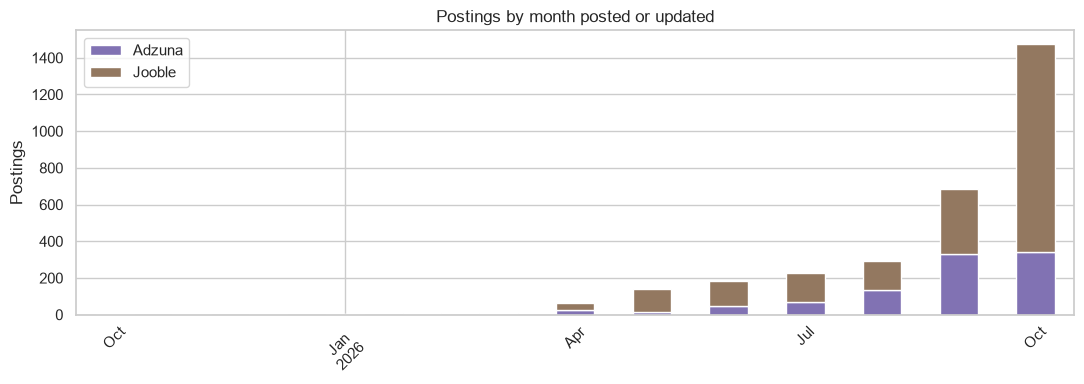

Records with a missing company: 135


,total_jobs,median_salary,cities
company,,,
Amazon,61,"153,300.00","Montreal, Toronto, Vancouver"
Lyft,56,"121,500.00","Montreal, Toronto"
AtkinsRéalis,55,"117,500.00","Montreal, Toronto, Vancouver"
Mercor,53,"195,000.00",Toronto
Deloitte,44,"87,500.00","Montreal, Toronto, Vancouver"
Aviso Wealth,27,"91,500.00","Montreal, Toronto, Vancouver"
Vancity,26,"117,025.00","Toronto, Vancouver"
Export Development Canada | Exportation et développement Can...,26,"112,650.00","Montreal, Toronto, Vancouver"
Capgemini,25,"110,000.00","Montreal, Toronto, Vancouver"


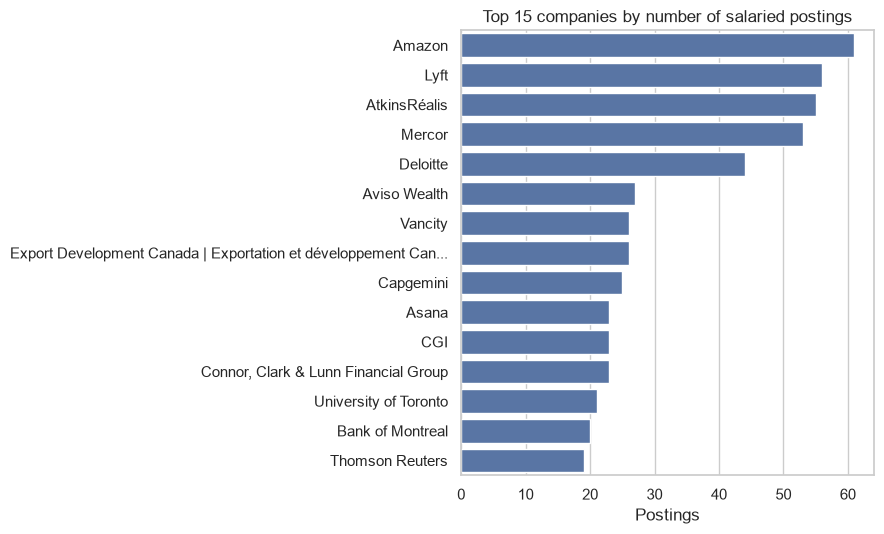

In [17]:
# ============================================================
# 9. POSTING DATES, COMPANIES, TITLES, WORK MODE AND SKILLS
# ============================================================
# NOTE: For Jooble, posted_date is the date the posting was last UPDATED.
# NOTE: Descriptions are short snippets (225 to 500 characters), so work mode
# and skills are under-counted. Use them only as a reference.

# --------------POSTING DATES-----------------
print("First posting date:", jobs["posted_date"].min())
print("Last posting date:", jobs["posted_date"].max())
print("Records with a missing posting date:", jobs["posted_date"].isna().sum())

postings_by_month = (jobs.dropna(subset=["posted_month"]).groupby(["posted_month", "source"]).size().unstack(fill_value=0))
ax = postings_by_month.plot(kind="bar", stacked=True, figsize=(11, 4), color=SOURCE_COLORS, rot=45)
ax.set_title("Postings by month posted or updated")
ax.set_xlabel("")
ax.set_ylabel("Postings")
ax.legend(title="")
save_figure("12_postings_by_month.png")

# --------------COMPANIES-----------------
print("Records with a missing company:", jobs["company"].isna().sum())

top_companies = (jobs.dropna(subset=["company"]).groupby("company")
                 .agg(total_jobs = ("title", "size"),
                      median_salary = ("salary_mid_annual", "median"),
                      cities = ("city", lambda s: ", ".join(sorted(set(s.astype(str))))))
                 .sort_values("total_jobs", ascending=False).head(15).round(0))
display(top_companies)
save_table(top_companies, "14_top_companies.csv")

plt.figure(figsize=(9, 5.5))
sns.barplot(x=top_companies["total_jobs"], y=top_companies.index, color="#4c72b0")
plt.title("Top 15 companies by number of salaried postings")
plt.xlabel("Postings")
plt.ylabel("")
save_figure("13_top_companies.png")

In [18]:
# --------------TITLES-----------------
# Most common titles in each job role and share of titles with a data-related term
for role in ROLES:
    role_jobs = jobs.loc[jobs["job_role"] == role]
    print(f"\n--- {role} ---")
    print("Records:", len(role_jobs))
    print("Titles with a data-related term (%):", round(role_jobs["title_has_data_term"].mean() * 100, 1))
    display(role_jobs["title"].value_counts().head(10))

salary_by_title_term = (jobs.groupby(["job_role", "title_has_data_term"], observed=True)
                        .agg(total_jobs = ("salary_mid_annual", "count"),
                             median_salary = ("salary_mid_annual", "median")).round(0))
print("Salary for titles with and without a data-related term:")
display(salary_by_title_term)
save_table(salary_by_title_term, "15_salary_by_title_data_term.csv")


--- Data Analyst ---
Records: 1522
Titles with a data-related term (%): 28.2


title
Senior Data Engineer        16
Business Analyst            14
Senior Financial Analyst    12
Data Analyst                11
Financial Analyst           10
Data Engineer                8
Data Scientist               7
Senior Business Analyst      7
Senior Product Manager       5
Customer Success Manager     5
Name: count, dtype: int64


--- Data Scientist ---
Records: 894
Titles with a data-related term (%): 38.4


title
Data Scientist                      12
Senior Data Engineer                 7
Senior Data Scientist                7
Senior Machine Learning Engineer     5
Data Engineer                        5
AI Engineer                          4
Solutions Architect                  3
Senior Software Engineer             3
Data Architect                       3
Senior Analytics Engineer            3
Name: count, dtype: int64


--- Data Engineer ---
Records: 962
Titles with a data-related term (%): 22.0


title
Senior Software Engineer     15
AI Engineer                   8
Senior Data Engineer          6
Senior Product Manager        5
Software Engineer             5
Machine Learning Engineer     5
Principal Engineer            4
Software Engineer II          4
Staff Software Engineer       4
Site Reliability Engineer     4
Name: count, dtype: int64

Salary for titles with and without a data-related term:


total_jobs  median_salary
job_role       title_has_data_term                           
Data Analyst   False                      1093      95,000.00
               True                        429     120,500.00
Data Scientist False                       551     125,000.00
               True                        343     136,000.00
Data Engineer  False                       750     140,000.00
               True                        212     142,675.00

work_mode,Hybrid,Not stated,On-site,Remote
city,,,,
Toronto,134,1331,37,61
Vancouver,25,1220,11,17
Montreal,32,468,17,25


job_role,Data Analyst,Data Scientist,Data Engineer,All roles
Machine learning,1.50,13.40,4.20,5.40
Python,0.70,1.10,2.60,1.40
SQL,1.40,0.70,2.00,1.40
Azure,0.70,0.90,2.10,1.20
Excel,1.50,0.80,0.50,1.00
AWS,0.40,0.80,2.10,1.00
Databricks,0.80,0.80,1.20,0.90
GCP,0.50,0.20,1.20,0.70
ETL,0.60,0.10,1.40,0.70
Power BI,0.60,0.20,0.50,0.50


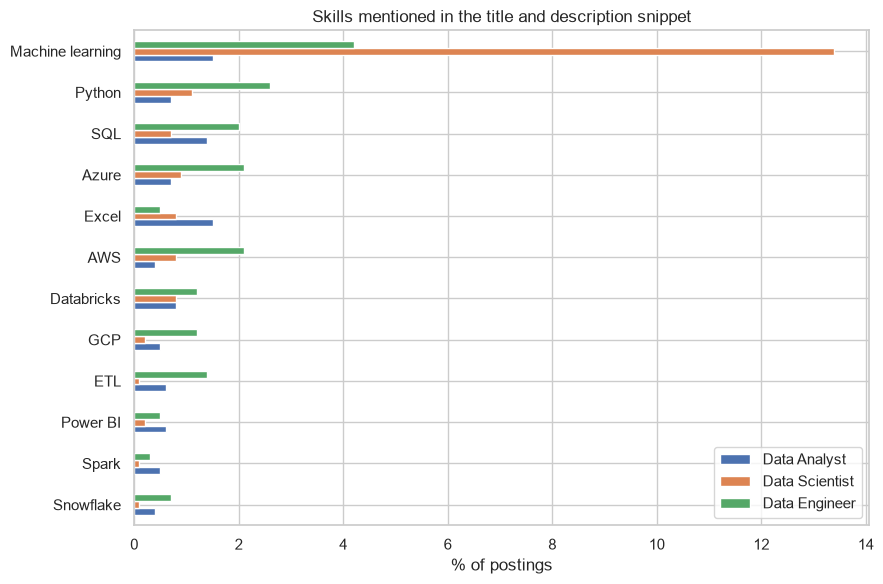

In [19]:
# --------------WORK MODE-----------------
work_mode_by_city = pd.crosstab(jobs["city"], jobs["work_mode"])
display(work_mode_by_city)
save_table(work_mode_by_city, "16_work_mode_by_city.csv")

# --------------SKILLS-----------------
SKILLS = {"Python": r"\bpython\b",
          "SQL": r"\bsql\b",
          "Excel": r"\bexcel\b",
          "Power BI": r"power ?bi",
          "Tableau": r"\btableau\b",
          "AWS": r"\baws\b",
          "Azure": r"\bazure\b",
          "GCP": r"\bgcp\b|google cloud",
          "Spark": r"\bspark\b",
          "Databricks": r"databricks",
          "Snowflake": r"snowflake",
          "ETL": r"\betl\b",
          "Machine learning": r"machine learning|\bml\b",
          "Airflow": r"airflow",
          "dbt": r"\bdbt\b",
          "SAS": r"\bsas\b",
          "Kafka": r"kafka",
          "Looker": r"looker"}

# Skills are searched in the title and the description snippet
job_text = (jobs["title"].fillna("") + " " + jobs["description"].fillna("")).str.lower()

skill_flags = pd.DataFrame()
for skill, pattern in SKILLS.items():
    skill_flags[skill] = job_text.str.contains(pattern, regex=True)

skills_by_role = (skill_flags.groupby(jobs["job_role"], observed=True).mean() * 100).round(1).T
skills_by_role["All roles"] = (skill_flags.mean() * 100).round(1)
skills_by_role = skills_by_role.sort_values("All roles", ascending=False)
display(skills_by_role)
save_table(skills_by_role, "17_skills_by_role.csv")

skills_by_role[ROLES].head(12).iloc[::-1].plot(kind="barh", figsize=(9, 6), color=[ROLE_COLORS[role] for role in ROLES])
plt.title("Skills mentioned in the title and description snippet")
plt.xlabel("% of postings")
plt.ylabel("")
plt.legend(title="")
save_figure("14_skills_by_role.png")

In [20]:
# ============================================================
# 10. PRELIMINARY STATISTICAL TESTS
# ============================================================
# Kruskal-Wallis is used because salaries are skewed and groups have different sizes.
# p-value < 0.05 means at least one group has a different salary distribution.
test_results = []

test_results.append(kruskal_test(jobs, "city", "Between cities (all roles)"))
test_results.append(kruskal_test(jobs, "job_role", "Between roles (all cities)"))

for role in ROLES:
    test_results.append(kruskal_test(jobs.loc[jobs["job_role"] == role], "city", f"Between cities | {role}"))

for city in CITIES:
    test_results.append(kruskal_test(jobs.loc[jobs["city"] == city], "job_role", f"Between roles | {city}"))

kruskal_report = pd.DataFrame(test_results)
kruskal_report["significant_at_5_percent"] = kruskal_report["p_value"] < 0.05
kruskal_report["p_value"] = kruskal_report["p_value"].apply(lambda x: f"{x:.2e}")
display(kruskal_report)
save_table(kruskal_report, "19_kruskal_wallis_tests.csv", index=False)

,comparison,groups,total_jobs,h_statistic,p_value,significant_at_5_percent
0,Between cities (all roles),3,3378,63.59,1.56e-14,True
1,Between roles (all cities),3,3378,307.43,1.75e-67,True
2,Between cities | Data Analyst,3,1522,15.29,4.79e-04,True
3,Between cities | Data Scientist,3,894,30.38,2.53e-07,True
4,Between cities | Data Engineer,3,962,4.65,9.79e-02,False
5,Between roles | Toronto,3,1563,162.15,6.17e-36,True
6,Between roles | Vancouver,3,1273,76.15,2.92e-17,True
7,Between roles | Montreal,3,542,64.01,1.26e-14,True


In [21]:
# ============================================================
# 11. SAVE DATASET AND EDA SUMMARY
# ============================================================
jobs.to_csv(output_folder / "jobs_eda_dataset.csv", index=False, encoding="utf-8-sig")

highest_group = salary_by_city_role["median_salary"].idxmax()
lowest_group = salary_by_city_role["median_salary"].idxmin()
smallest_group = salary_by_city_role["total_jobs"].idxmin()
senior_share = jobs["seniority"].isin(["Senior", "Lead / Manager"]).mean() * 100

# Overall EDA Summary
eda_summary = pd.DataFrame({"Metric": ["Records in jobs_clean.csv",
                                       "Records used in the EDA",
                                       "Overall median salary",
                                       "Median salary Toronto",
                                       "Median salary Vancouver",
                                       "Median salary Montreal",
                                       "Median salary Data Analyst",
                                       "Median salary Data Scientist",
                                       "Median salary Data Engineer",
                                       "Highest median (city | role)",
                                       "Lowest median (city | role)",
                                       "Smallest group (city | role)",
                                       "Senior or lead titles (%)"],
                            "Value": [len(jobs_raw),
                                      len(jobs),
                                      round(jobs["salary_mid_annual"].median()),
                                      salary_by_city.loc["Toronto", "median_salary"],
                                      salary_by_city.loc["Vancouver", "median_salary"],
                                      salary_by_city.loc["Montreal", "median_salary"],
                                      salary_by_role.loc["Data Analyst", "median_salary"],
                                      salary_by_role.loc["Data Scientist", "median_salary"],
                                      salary_by_role.loc["Data Engineer", "median_salary"],
                                      f"{highest_group[0]} | {highest_group[1]}",
                                      f"{lowest_group[0]} | {lowest_group[1]}",
                                      f"{smallest_group[0]} | {smallest_group[1]}",
                                      round(senior_share, 1)]})
display(eda_summary)
save_table(eda_summary, "20_eda_summary.csv", index=False)

print("Figures saved in:", figures_folder.relative_to(PROJECT_ROOT))
print("Tables saved in:", tables_folder.relative_to(PROJECT_ROOT))
print("Final dataset shape:", jobs.shape)

,Metric,Value
0,Records in jobs_clean.csv,3558
1,Records used in the EDA,3378
2,Overall median salary,120000
3,Median salary Toronto,"126,750.00"
4,Median salary Vancouver,"118,500.00"
5,Median salary Montreal,"104,994.00"
6,Median salary Data Analyst,"102,000.00"
7,Median salary Data Scientist,"131,812.00"
8,Median salary Data Engineer,"141,278.00"
9,Highest median (city | role),Toronto | Data Engineer


Figures saved in: output/eda_jobs/figures
Tables saved in: output/eda_jobs/tables
Final dataset shape: (3378, 29)
